# 21 Live inference analysis (leave-one-subject-out, session 1)

Every recording is classified by a model that has **never seen its subject**:
the leave-one-subject-out models `fixed_<subject>.pt2` and `robust_<subject>.pt2` (fixed and robust epochs, trained on all other subjects).
This removes the training-set caveat of notebook 21. The classifier's own functions are used for everything (filters, windowing,
z-scoring, fine tuning, pinch detector, hit matching); the glue code lives in `scripts/live_inference.py`.

**Live pipeline (replayed offline).** The EEG is average referenced (with the Pz recording reference restored), filtered causally
(1 Hz high-pass, 45 Hz low-pass, 50 Hz notch), and every `HOP` seconds the last 2 s are z-scored per channel and classified. A pinch
is triggered once `n` consecutive windows have p(pinch) > `p`. A detection at time t is a hit if an unmatched ground-truth pinch lies in
(t − 2 s, t]; precision / recall / F scores follow from hits, false alarms and misses (accuracy = TP / (TP + FP + FN), as there are no true
negatives in pinch detection). All counts are summed over the subjects unless stated otherwise.

**Data.** First session of every subject with two sessions. The experiments with **hinted pinches are skipped entirely** (two of the twelve
per session): none of their windows, pinches or epochs are used, the EEG just keeps running through them as it would live. Of the remaining
ten experiments, the first five play the role of phase 1 of a live run (fine tuning and detector optimization) and the last five are the
test set. `subject_36` and `subject_40` are skipped: they only have one recording, which has the eight-experiment layout of session 2.

**Runs.**
1. *Original*: the leave-one-subject-out models, with the default detector (`DETECTOR_CONSECUTIVE` / `DETECTOR_THRESHOLD`) and with the
   detector optimized on the first half (as `LiveEEGClassifier` does after phase 1).
2. *Fine-tuned*: the models are fine tuned on the first half (`LiveEEGClassifier.finetune`), the detector is optimized on the first half,
   and the second half is the test set. The fine tuning settings are first optimized on **session 2** (same split, hinted experiments
   skipped as well), so session 1 stays untouched for the comparison.

In [1]:
%load_ext autoreload
%autoreload 2

import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

from scripts import paper_style  # two-column paper style for every figure (sizes/font in scripts/paper_style.py)
from scripts.paper_style import COL_W, TEXT_W, CAT_COLORS, enforce_font_sizes
from scripts import live_inference as li

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 40)

In [2]:
INPUT_DIR = pathlib.Path('data/raw')
OUT_DIR = pathlib.Path('out/live_inference_loso')
OUT_DIR_FIG = pathlib.Path('out/figs')

# leave-one-subject-out models: every recording is classified by the model trained without its subject
MODELS = {
    'fixed': lambda rec: f'fixed_{rec.subject}.pt2',
    'robust': lambda rec: f'robust_{rec.subject}.pt2',
}
TEST_SESSION = 1     # final evaluation
TUNE_SESSION = 2     # selection of the fine tuning settings
SKIP_HINTED = True   # drop the experiments with hinted pinches entirely
HOP = 0.25           # seconds between classifications (--hop of LiveEEGClassifier)
F_BETA = 0.5         # detector / fine tuning objective of interest; 1 -> F1 (what LiveEEGClassifier optimizes), 0.5 weights precision higher
RECOMPUTE = True    # the runs are cached in OUT_DIR

## Recordings

Experiments with hinted pinches are skipped (`SKIP_HINTED`). Ground-truth pinches are all `PinchLog` events except gaze selections (every pinch type is a hand movement), with double activations
removed and delayed-feedback pinches moved back by 0.5 s, as in 11_preprocessing. The no-pinch events used for fine tuning are drawn
like in `LiveEEGClassifier` (one per gap of ≥ 2 × 1.1 s between two pinches, seeded).

In [3]:
# only subjects with both sessions: subject_36 and subject_40 have a single recording with the eight-experiment layout of session 2
subjects = sorted(d for d in INPUT_DIR.iterdir() if d.is_dir() and len(li._recording_files(d)) >= 2)
print('skipped (single recording):', sorted(d.name for d in INPUT_DIR.iterdir() if d.is_dir() and d not in subjects))

def load_sessions(session):
    return [li.load_study_session(d, session, skip_hinted=SKIP_HINTED) for d in subjects]

def overview(recs):
    return pd.DataFrame([{
        'recording': r.name,
        'train experiments': len(r.train_intervals),
        'test experiments': len(r.test_intervals),
        'train pinches': li.in_intervals(r.pos_ts, r.train_intervals).sum(),
        'train no pinch': li.in_intervals(r.neg_ts, r.train_intervals).sum(),
        'test pinches': li.in_intervals(r.pos_ts, r.test_intervals).sum(),
        'test minutes': sum(e - s for s, e in r.test_intervals) / 60,
    } for r in recs]).round(1)

recs_tune = load_sessions(TUNE_SESSION)
recs_test = load_sessions(TEST_SESSION)
missing = sorted({m(r) for r in recs_test for m in MODELS.values() if not pathlib.Path(m(r)).exists()})
assert not missing, f'missing leave-one-subject-out models: {missing}'
overview(recs_test)

skipped (single recording): ['subject_36', 'subject_40']


,recording,train experiments,test experiments,train pinches,train no pinch,test pinches,test minutes
0,subject_21/session_1,5,5,77,65,79,8.6
1,subject_22/session_1,5,5,78,68,80,8.4
2,subject_23/session_1,5,5,83,72,69,8.5
3,subject_24/session_1,5,5,85,71,70,9.1
4,subject_25/session_1,5,5,79,66,86,9.2
5,subject_26/session_1,5,5,78,66,78,8.6
6,subject_27/session_1,5,5,84,67,77,8.8
7,subject_28/session_1,5,5,80,70,77,9.2
8,subject_29/session_1,5,5,73,60,81,8.1
9,subject_30/session_1,5,5,80,68,73,8.4


In [4]:
DETECTOR_LABELS = {
    'default': f'default (n={li.DEFAULT_DETECTOR[0]}, p>{li.DEFAULT_DETECTOR[1]})',
    'opt_F1': 'optimized for F1 on 1st half',
    'opt_F0.5': 'optimized for F0.5 on 1st half',
    'oracle_F1': 'optimized for F1 on test half (upper bound)',
    'oracle_F0.5': 'optimized for F0.5 on test half (upper bound)',
}
F_COL = {1.0: 'f1', 0.5: 'f05'}[F_BETA]
OPT = f'opt_F{F_BETA:g}'

def summary_table(rows, detector, by=('model', 'run')):
    """Hits / false alarms / misses pooled over the recordings; 'F1 / F0.5 (mean)' average the per-recording scores and
    n / p are the median detector settings."""
    by = list(by)
    sel = rows[rows.detector == detector]
    t = li.pooled(sel, by)
    g = sel.groupby(by, sort=False)
    t = t.merge(g.agg(n=('consecutive', 'median'), p=('threshold', 'median'),
                      f1_mean=('f1', 'mean'), f05_mean=('f05', 'mean')).reset_index(), on=by)
    t['n / p'] = [f'{n:g} / {p:.3g}' for n, p in zip(t.n, t.p)]
    t['hits / FA / misses'] = [f'{h} / {f} / {m}' for h, f, m in zip(t.hits, t.false_alarms, t.misses)]
    cols = by + ['n / p', 'hits / FA / misses', 'precision', 'recall', 'accuracy', 'f1', 'f05', 'f1_mean', 'f05_mean', 'auc_test']
    return t[cols].rename(columns={'f1': 'F1', 'f05': 'F0.5', 'f1_mean': 'F1 (mean)', 'f05_mean': 'F0.5 (mean)',
                                   'auc_test': 'window AUC'}).round(3)

## Run 1: original models

The leave-one-subject-out models on the second half of session 1, without fine tuning.

In [5]:
rows_orig, traces_orig = li.run_grid(recs_test, MODELS, {'original': None}, hop=HOP,
                                     cache=OUT_DIR / 'test_original.pkl', recompute=RECOMPUTE)
for det in ['default', 'opt_F1', 'opt_F0.5', 'oracle_F1', 'oracle_F0.5']:
    print(DETECTOR_LABELS[det])
    display(summary_table(rows_orig, det))

C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
recordings: 100%|██████████| 17/17 [02:46<00:00,  9.79s/it]

default (n=2, p>0.7)


,model,run,n / p,hits / FA / misses,precision,recall,accuracy,F1,F0.5,F1 (mean),F0.5 (mean),window AUC
0,fixed,original,2 / 0.7,515 / 731 / 796,0.413,0.393,0.252,0.403,0.409,0.392,0.406,0.713
1,robust,original,2 / 0.7,268 / 369 / 1043,0.421,0.204,0.160,0.275,0.347,0.245,0.302,0.623


optimized for F1 on 1st half


,model,run,n / p,hits / FA / misses,precision,recall,accuracy,F1,F0.5,F1 (mean),F0.5 (mean),window AUC
0,fixed,original,2 / 0.55,605 / 1033 / 706,0.369,0.461,0.258,0.410,0.385,0.402,0.380,0.713
1,robust,original,2 / 0.525,523 / 891 / 788,0.370,0.399,0.238,0.384,0.375,0.375,0.373,0.623


...

,model,run,n / p,hits / FA / misses,precision,recall,accuracy,F1,F0.5,F1 (mean),F0.5 (mean),window AUC
0,fixed,original,3 / 0.575,354 / 444 / 957,0.444,0.270,0.202,0.336,0.393,0.330,0.388,0.713
1,robust,original,3 / 0.55,303 / 424 / 1008,0.417,0.231,0.175,0.297,0.359,0.286,0.341,0.623


optimized for F1 on test half (upper bound)


,model,run,n / p,hits / FA / misses,precision,recall,accuracy,F1,F0.5,F1 (mean),F0.5 (mean),window AUC
0,fixed,original,2 / 0.525,826 / 1430 / 485,0.366,0.630,0.301,0.463,0.400,0.470,0.411,0.713
1,robust,original,2 / 0.55,569 / 845 / 742,0.402,0.434,0.264,0.418,0.408,0.406,0.397,0.623


optimized for F0.5 on test half (upper bound)


,model,run,n / p,hits / FA / misses,precision,recall,accuracy,F1,F0.5,F1 (mean),F0.5 (mean),window AUC
0,fixed,original,3 / 0.65,461 / 464 / 850,0.498,0.352,0.260,0.412,0.460,0.409,0.467,0.713
1,robust,original,3 / 0.6,392 / 352 / 919,0.527,0.299,0.236,0.382,0.457,0.369,0.440,0.623


## Fine tuning settings (optimized on session 2)

`LiveEEGClassifier` fine tunes for `FINETUNE_EPOCHS` epochs with Adam (`FINETUNE_LR`, `FINETUNE_BATCH_SIZE`) and keeps the weights with the
lowest validation loss (20 % of the phase 1 epochs). Besides the optimizer settings, the *fine tuning data* is compared:

- `mne` (current): epochs as in `build_finetune_dataset`, i.e. zero-phase MNE filters and channel-wise z-scoring over the whole dataset
  (the preprocessing the models were trained with);
- `live`: the windows the live pipeline actually classifies (causal filters, per-window z-scoring), aligned like the epochs (−1.7 s to
  +0.3 s around the event).

Each setting is scored on the second half of **session 2** (hinted experiments skipped) after fine tuning on its first half. The selection criterion is the
threshold-free window AUC on the test half, averaged over subjects and both models (the same settings are used for both models in
`LiveEEGClassifier`). The F-scores of the detector optimized on the first half are shown as well, but they differ by only a few
hundredths between all settings, which is within the noise of the threshold choice, so they are not used for the selection.

In [6]:
LRS = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3]
FINETUNE_GRID = {f'{data} lr={lr:g}': dict(data=data, lr=lr) for data in ['mne', 'live'] for lr in LRS}

rows_hp, _ = li.run_grid(recs_tune, MODELS, {'original': None, **FINETUNE_GRID}, hop=HOP, keep_traces=False,
                         cache=OUT_DIR / 'tune_finetune_grid.pkl', recompute=RECOMPUTE)

def hp_scores(rows):
    """Per fine tuning run: pooled F-beta of the optimized detectors and mean window AUC on the test half, per model and averaged."""
    out = []
    for det in ['opt_F1', 'opt_F0.5']:
        p = li.pooled(rows[rows.detector == det], ['run', 'model'])
        out.append(p.pivot(index='run', columns='model', values='f1' if det == 'opt_F1' else 'f05').add_prefix(f'{det} '))
    auc = rows[rows.detector == 'default'].groupby(['run', 'model']).auc_test.mean().unstack().add_prefix('AUC ')
    t = pd.concat(out + [auc], axis=1)
    for m in ['opt_F1', 'opt_F0.5', 'AUC']:
        t[f'{m} mean'] = t[[f'{m} {model}' for model in MODELS]].mean(axis=1)
    return t

scores_hp = hp_scores(rows_hp)
scores_hp.sort_values('AUC mean', ascending=False).round(3)

recordings:   0%|          | 0/17 [00:00<?, ?it/s]C:\Users\nicol\github\VIBE\LSLService\LiveEEGClassifier.py:576: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  raw.set_montage(mne.channels.make_standard_montage("standard_1020"), on_missing="ignore")
C:\Users\nicol\github\VIBE\LSLService\LiveEEGClassifier.py:576: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  raw.set_montage(mne.channels.make_standard_montage("standard_1020"), on_missing="ignore")
C:\Users\nicol\github\VIBE\LSLService\LiveEEGClassifier.py:576: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  raw.set_montage(mne.channels.make_standard_montage("standard_1020"), on_missing="ignore")
C:\Users\nicol\github\VIBE\LSLService\LiveEEGClassifier.py:576: FutureWarning: Montage name 'standard_1020' is deprecated and

model,opt_F1 fixed,opt_F1 robust,opt_F0.5 fixed,opt_F0.5 robust,AUC fixed,AUC robust,opt_F1 mean,opt_F0.5 mean,AUC mean
run,,,,,,,,,
live lr=0.001,0.466,0.415,0.459,0.398,0.791,0.708,0.441,0.428,0.750
live lr=0.0003,0.475,0.416,0.430,0.394,0.790,0.691,0.445,0.412,0.741
mne lr=0.0003,0.467,0.395,0.421,0.409,0.785,0.690,0.431,0.415,0.738
mne lr=0.001,0.466,0.422,0.425,0.394,0.774,0.697,0.444,0.409,0.735
live lr=0.0001,0.460,0.386,0.448,0.383,0.787,0.677,0.423,0.416,0.732
mne lr=0.0001,0.459,0.372,0.425,0.390,0.782,0.674,0.415,0.407,0.728
live lr=3e-05,0.449,0.397,0.403,0.374,0.783,0.668,0.423,0.389,0.725
mne lr=3e-05,0.445,0.393,0.418,0.375,0.780,0.666,0.419,0.396,0.723
live lr=1e-05,0.452,0.384,0.409,0.384,0.781,0.664,0.418,0.396,0.723


The batch size and the number of epochs are then varied around the best setting, one at a time (plus a higher learning rate if the best one is at the edge of the grid).

In [7]:
best_run = scores_hp.drop(index='original')['AUC mean'].idxmax()
best_stage1 = {**li.DEFAULT_FINETUNE, **FINETUNE_GRID[best_run]}
print('best data / learning rate:', best_run)

FINETUNE_GRID_2 = {}
if best_stage1['lr'] == max(LRS):   # best learning rate at the edge of the grid: also try one step higher
    FINETUNE_GRID_2[f"{best_stage1['data']} lr={3 * best_stage1['lr']:g}"] = {**best_stage1, 'lr': 3 * best_stage1['lr']}
for epochs in [15, 60]:
    FINETUNE_GRID_2[f'{best_run} epochs={epochs}'] = {**best_stage1, 'epochs': epochs}
for batch_size in [16, 64]:
    FINETUNE_GRID_2[f'{best_run} batch={batch_size}'] = {**best_stage1, 'batch_size': batch_size}

rows_hp2, _ = li.run_grid(recs_tune, MODELS, FINETUNE_GRID_2, hop=HOP, keep_traces=False,
                          cache=OUT_DIR / f'tune_finetune_grid2_{best_run.replace(" ", "_")}.pkl', recompute=RECOMPUTE)
rows_hp_all = pd.concat([rows_hp, rows_hp2], ignore_index=True)
all_grids = {'original': None, **FINETUNE_GRID, **FINETUNE_GRID_2}

scores_hp_all = hp_scores(rows_hp_all)
best_run = scores_hp_all.drop(index='original')['AUC mean'].idxmax()
BEST_FINETUNE = {**li.DEFAULT_FINETUNE, **all_grids[best_run]}
print('selected fine tuning settings:', best_run, BEST_FINETUNE)
print('current LiveEEGClassifier settings:', li.DEFAULT_FINETUNE)
scores_hp_all.sort_values('AUC mean', ascending=False).round(3)

best data / learning rate: live lr=0.001


recordings: 100%|██████████| 17/17 [15:52<00:00, 56.02s/it]

selected fine tuning settings: live lr=0.001 batch=16 {'lr': 0.001, 'epochs': 30, 'batch_size': 16, 'data': 'live'}
current LiveEEGClassifier settings: {'lr': 0.0001, 'epochs': 30, 'batch_size': 32, 'data': 'mne'}


model,opt_F1 fixed,opt_F1 robust,opt_F0.5 fixed,opt_F0.5 robust,AUC fixed,AUC robust,opt_F1 mean,opt_F0.5 mean,AUC mean
run,,,,,,,,,
live lr=0.001 batch=16,0.448,0.420,0.413,0.394,0.787,0.719,0.434,0.403,0.753
live lr=0.001 epochs=60,0.457,0.407,0.452,0.392,0.786,0.719,0.432,0.422,0.753
live lr=0.001 batch=64,0.466,0.415,0.459,0.398,0.791,0.708,0.441,0.428,0.750
live lr=0.001,0.466,0.415,0.459,0.398,0.791,0.708,0.441,0.428,0.750
live lr=0.003,0.441,0.387,0.450,0.388,0.779,0.718,0.414,0.419,0.748
live lr=0.001 epochs=15,0.471,0.407,0.459,0.414,0.793,0.699,0.439,0.437,0.746
live lr=0.0003,0.475,0.416,0.430,0.394,0.790,0.691,0.445,0.412,0.741
mne lr=0.0003,0.467,0.395,0.421,0.409,0.785,0.690,0.431,0.415,0.738
mne lr=0.001,0.466,0.422,0.425,0.394,0.774,0.697,0.444,0.409,0.735


findfont: Failed to find font weight 300 for STIXGeneral, now using 400.
findfont: Failed to find font weight 300 for STIXGeneral, now using 400.
findfont: Failed to find font weight 300 for STIXNonUnicode, now using 400.
findfont: Failed to find font weight 300 for STIXNonUnicode, now using 400.
findfont: Failed to find font weight 300 for STIXSizeOneSym, now using 400.
findfont: Failed to find font weight 300 for STIXSizeTwoSym, now using 400.
findfont: Failed to find font weight 300 for STIXSizeThreeSym, now using 400.
findfont: Failed to find font weight 300 for STIXSizeFourSym, now using 400.
findfont: Failed to find font weight 300 for STIXSizeFiveSym, now using 400.
findfont: Failed to find font weight 300 for cmmi10, now using 400.
findfont: Failed to find font weight 300 for cmsy10, now using 400.
findfont: Failed to find font weight 300 for cmr10, now using 400.
findfont: Failed to find font weight 300 for cmtt10, now using 400.
findfont: Failed to find font weight 300 for cm

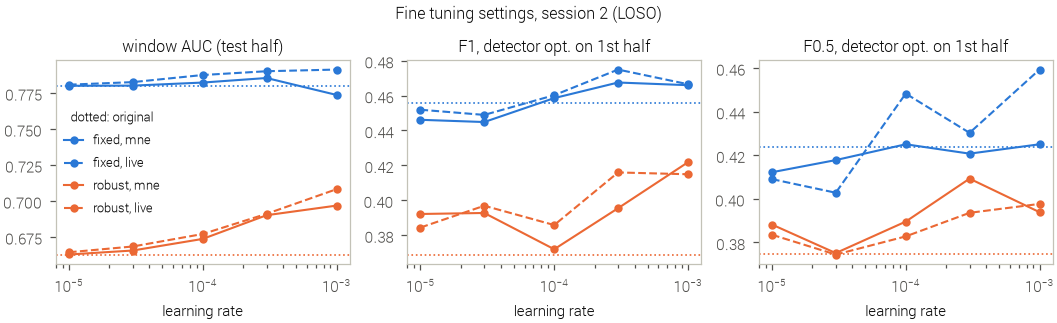

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(TEXT_W, 2.2), layout='constrained', sharex=True)
for ax, (metric, label) in zip(axes, [('AUC', 'window AUC (test half)'), ('opt_F1', 'F1, detector opt. on 1st half'),
                                      ('opt_F0.5', 'F0.5, detector opt. on 1st half')]):
    for i, model in enumerate(MODELS):
        ax.axhline(scores_hp.loc['original', f'{metric} {model}'], color=CAT_COLORS[i], lw=0.8, ls=':')
        for data, ls in [('mne', '-'), ('live', '--')]:
            ax.plot(LRS, [scores_hp.loc[f'{data} lr={lr:g}', f'{metric} {model}'] for lr in LRS],
                    color=CAT_COLORS[i], ls=ls, marker='o', ms=3, label=f'{model}, {data}')
    ax.set_xscale('log')
    ax.set_xlabel('learning rate')
    ax.set_title(label)
axes[0].legend(title='dotted: original', frameon=False)
fig.suptitle('Fine tuning settings, session 2 (LOSO)')
enforce_font_sizes(fig)
plt.show()

## Run 2: fine tuning on the first half of session 1

Both models are fine tuned on the first half with the current settings of `LiveEEGClassifier` and with the settings selected on session 2;
the detector is optimized on the first half and everything is scored on the second half.

In [9]:
FINETUNES = {
    'fine-tuned (current)': li.DEFAULT_FINETUNE,
    'fine-tuned (optimized)': BEST_FINETUNE,
}
rows_ft, traces_ft = li.run_grid(recs_test, MODELS, FINETUNES, hop=HOP,
                                 cache=OUT_DIR / f'test_finetuned_{best_run.replace(" ", "_")}.pkl', recompute=RECOMPUTE)
rows_test = pd.concat([rows_orig, rows_ft], ignore_index=True)
traces_test = {**traces_orig, **traces_ft}
rows_test.to_csv(OUT_DIR / 'test_results.csv', index=False)

recordings:   0%|          | 0/17 [00:00<?, ?it/s]C:\Users\nicol\github\VIBE\LSLService\LiveEEGClassifier.py:576: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  raw.set_montage(mne.channels.make_standard_montage("standard_1020"), on_missing="ignore")
C:\Users\nicol\github\VIBE\LSLService\LiveEEGClassifier.py:576: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  raw.set_montage(mne.channels.make_standard_montage("standard_1020"), on_missing="ignore")
recordings:   6%|▌         | 1/17 [00:41<11:02, 41.43s/it]C:\Users\nicol\github\VIBE\LSLService\LiveEEGClassifier.py:576: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  raw.set_montage(mne.channels.make_standard_montage("standard_1020"), on_missing="ignore")
C:\Users\nicol\github\VIBE\LSLService\LiveEEGClassifier.py:576: Fut

## Comparison

In [10]:
for det in ['opt_F1', 'opt_F0.5', 'default', 'oracle_F1', 'oracle_F0.5']:
    print(DETECTOR_LABELS[det])
    display(summary_table(rows_test, det))

summary = pd.concat([summary_table(rows_test, det).assign(detector=det) for det in DETECTOR_LABELS], ignore_index=True)
summary.to_csv(OUT_DIR / 'test_summary.csv', index=False)

optimized for F1 on 1st half


,model,run,n / p,hits / FA / misses,precision,recall,accuracy,F1,F0.5,F1 (mean),F0.5 (mean),window AUC
0,fixed,original,2 / 0.55,605 / 1033 / 706,0.369,0.461,0.258,0.410,0.385,0.402,0.380,0.713
1,robust,original,2 / 0.525,523 / 891 / 788,0.370,0.399,0.238,0.384,0.375,0.375,0.373,0.623
2,fixed,fine-tuned (current),2 / 0.6,641 / 998 / 670,0.391,0.489,0.278,0.435,0.407,0.430,0.408,0.717
3,fixed,fine-tuned (optimized),3 / 0.575,627 / 874 / 684,0.418,0.478,0.287,0.446,0.429,0.446,0.440,0.756
4,robust,fine-tuned (current),2 / 0.55,524 / 816 / 787,0.391,0.400,0.246,0.395,0.393,0.395,0.401,0.641
5,robust,fine-tuned (optimized),4 / 0.575,555 / 854 / 756,0.394,0.423,0.256,0.408,0.399,0.409,0.412,0.697


optimized for F0.5 on 1st half


,model,run,n / p,hits / FA / misses,precision,recall,accuracy,F1,F0.5,F1 (mean),F0.5 (mean),window AUC
0,fixed,original,3 / 0.575,354 / 444 / 957,0.444,0.270,0.202,0.336,0.393,0.330,0.388,0.713
1,robust,original,3 / 0.55,303 / 424 / 1008,0.417,0.231,0.175,0.297,0.359,0.286,0.341,0.623
2,fixed,fine-tuned (current),3 / 0.675,375 / 422 / 936,0.471,0.286,0.216,0.356,0.417,0.348,0.406,0.717
3,fixed,fine-tuned (optimized),3 / 0.625,459 / 533 / 852,0.463,0.350,0.249,0.399,0.435,0.395,0.438,0.756
4,robust,fine-tuned (current),5 / 0.525,380 / 511 / 931,0.426,0.290,0.209,0.345,0.390,0.340,0.384,0.641
5,robust,fine-tuned (optimized),5 / 0.6,335 / 358 / 976,0.483,0.256,0.201,0.334,0.410,0.322,0.394,0.697


default (n=2, p>0.7)


,model,run,n / p,hits / FA / misses,precision,recall,accuracy,F1,F0.5,F1 (mean),F0.5 (mean),window AUC
0,fixed,original,2 / 0.7,515 / 731 / 796,0.413,0.393,0.252,0.403,0.409,0.392,0.406,0.713
1,robust,original,2 / 0.7,268 / 369 / 1043,0.421,0.204,0.160,0.275,0.347,0.245,0.302,0.623
2,fixed,fine-tuned (current),2 / 0.7,535 / 782 / 776,0.406,0.408,0.256,0.407,0.407,0.397,0.408,0.717
3,fixed,fine-tuned (optimized),2 / 0.7,650 / 1053 / 661,0.382,0.496,0.275,0.431,0.400,0.427,0.399,0.756
4,robust,fine-tuned (current),2 / 0.7,333 / 492 / 978,0.404,0.254,0.185,0.312,0.361,0.289,0.335,0.641
5,robust,fine-tuned (optimized),2 / 0.7,502 / 779 / 809,0.392,0.383,0.240,0.387,0.390,0.364,0.375,0.697


optimized for F1 on test half (upper bound)


,model,run,n / p,hits / FA / misses,precision,recall,accuracy,F1,F0.5,F1 (mean),F0.5 (mean),window AUC
0,fixed,original,2 / 0.525,826 / 1430 / 485,0.366,0.630,0.301,0.463,0.400,0.470,0.411,0.713
1,robust,original,2 / 0.55,569 / 845 / 742,0.402,0.434,0.264,0.418,0.408,0.406,0.397,0.623
2,fixed,fine-tuned (current),2 / 0.575,758 / 1098 / 553,0.408,0.578,0.315,0.479,0.434,0.484,0.446,0.717
3,fixed,fine-tuned (optimized),3 / 0.55,780 / 1066 / 531,0.423,0.595,0.328,0.494,0.449,0.504,0.467,0.756
4,robust,fine-tuned (current),3 / 0.525,661 / 874 / 650,0.431,0.504,0.303,0.465,0.444,0.467,0.452,0.641
5,robust,fine-tuned (optimized),3 / 0.55,681 / 905 / 630,0.429,0.519,0.307,0.470,0.445,0.477,0.466,0.697


optimized for F0.5 on test half (upper bound)


,model,run,n / p,hits / FA / misses,precision,recall,accuracy,F1,F0.5,F1 (mean),F0.5 (mean),window AUC
0,fixed,original,3 / 0.65,461 / 464 / 850,0.498,0.352,0.260,0.412,0.460,0.409,0.467,0.713
1,robust,original,3 / 0.6,392 / 352 / 919,0.527,0.299,0.236,0.382,0.457,0.369,0.440,0.623
2,fixed,fine-tuned (current),3 / 0.65,470 / 431 / 841,0.522,0.359,0.270,0.425,0.478,0.422,0.482,0.717
3,fixed,fine-tuned (optimized),3 / 0.575,558 / 526 / 753,0.515,0.426,0.304,0.466,0.494,0.464,0.497,0.756
4,robust,fine-tuned (current),3 / 0.6,518 / 508 / 793,0.505,0.395,0.285,0.443,0.478,0.439,0.482,0.641
5,robust,fine-tuned (optimized),4 / 0.55,504 / 482 / 807,0.511,0.384,0.281,0.439,0.480,0.437,0.491,0.697


In [21]:
# values for the table of simulated online classification results: original models (no fine tuning), detector optimized for
# F_BETA on the first half; hits / false alarms / misses summed over the subjects, n / p are the median detector settings,
# all scores in % (hit rate = hits / pinches = recall, miss rate = misses / pinches), false alarms per minute of test time (experiments of the test half only)
def online_table(rows, recs, detector=OPT, run='original'):
    sel = rows[(rows.run == run) & (rows.detector == detector)]
    t = li.pooled(sel, ['model']).set_index('model')
    med = sel.groupby('model')[['consecutive', 'threshold']].median()
    minutes = sum(e - s for r in recs for s, e in r.test_intervals) / 60
    return pd.DataFrame({
        'n/p': [f'{med.consecutive[m]:g}/{med.threshold[m]:g}' for m in t.index],
        'H/FA/M': [f'{t.hits[m]}/{t.false_alarms[m]}/{t.misses[m]}' for m in t.index],
        'P': 100 * t.precision, 'R': 100 * t.recall, 'Acc': 100 * t.accuracy, 'F1': 100 * t.f1, 'F0.5': 100 * t.f05,
        'hit rate': 100 * t.hits / (t.hits + t.misses), 'miss rate': 100 * t.misses / (t.hits + t.misses),
        'FA/min': t.false_alarms / minutes,
    }, index=t.index).loc[list(MODELS)], minutes

online, test_minutes = online_table(rows_test, recs_test)
print(f'{len(recs_test)} subjects, {test_minutes:.1f} min of test data, detector optimized for F{F_BETA:g} on the first half')
display(online.round(1))

for model, r in online.iterrows():
    print(rf'    \multicolumn{{8}}{{@{{}}l}}{{\textit{{{model.capitalize()}}}}} \\')
    print(rf'    \quad Original   & {r["n/p"]} & {r["H/FA/M"]} & {r.P:.1f} & {r.R:.1f} & {r.Acc:.1f} & {r.F1:.1f} & {r["F0.5"]:.1f} \\'
          f'   % {r["FA/min"]:.2f} FA/min')

17 subjects, 146.0 min of test data, detector optimized for F0.5 on the first half


,n/p,H/FA/M,P,R,Acc,F1,F0.5,FA/min
model,,,,,,,,
fixed,3/0.575,354/444/957,44.4,27.0,20.2,33.6,39.3,3.0
robust,3/0.55,303/424/1008,41.7,23.1,17.5,29.7,35.9,2.9


    \multicolumn{8}{@{}l}{\textit{Fixed}} \\
    \quad Original   & 3/0.575 & 354/444/957 & 44.4 & 27.0 & 20.2 & 33.6 & 39.3 \\   % 3.04 FA/min
    \multicolumn{8}{@{}l}{\textit{Robust}} \\
    \quad Original   & 3/0.55 & 303/424/1008 & 41.7 & 23.1 & 17.5 & 29.7 & 35.9 \\   % 2.90 FA/min


Per subject: F-beta of the detector optimized on the first half and the threshold-free window AUC, original vs. fine tuned. The paired
Wilcoxon signed-rank test compares each fine tuned run with the original model over subjects.

In [11]:
RUNS = ['original', 'fine-tuned (current)', 'fine-tuned (optimized)']

def paired_tests(rows, detector):
    out = []
    sel = rows[rows.detector == detector]
    for model in MODELS:
        for metric in ['f1', 'f05', 'precision', 'recall', 'auc_test']:
            piv = sel[sel.model == model].pivot(index='recording', columns='run', values=metric)
            for run in RUNS[1:]:
                d = (piv[run] - piv['original']).dropna()
                p = wilcoxon(d).pvalue if (d != 0).any() else np.nan
                out.append(dict(model=model, metric=metric, run=run, mean_original=piv['original'].mean(),
                                mean_run=piv[run].mean(), mean_diff=d.mean(), improved=(d > 0).sum(), worse=(d < 0).sum(), p=p))
    return pd.DataFrame(out).round(4)

paired_tests(rows_test, OPT)

,model,metric,run,mean_original,mean_run,mean_diff,improved,worse,p
0,fixed,f1,fine-tuned (current),0.3301,0.3481,0.0180,10,7,0.3060
1,fixed,f1,fine-tuned (optimized),0.3301,0.3946,0.0645,12,4,0.0437
2,fixed,f05,fine-tuned (current),0.3883,0.4057,0.0174,10,7,0.4038
3,fixed,f05,fine-tuned (optimized),0.3883,0.4375,0.0492,12,4,0.0787
4,fixed,precision,fine-tuned (current),0.4567,0.4699,0.0132,8,9,0.5791
5,fixed,precision,fine-tuned (optimized),0.4567,0.4846,0.0279,11,5,0.2146
6,fixed,recall,fine-tuned (current),0.2748,0.2926,0.0178,7,6,0.3109
7,fixed,recall,fine-tuned (optimized),0.2748,0.3560,0.0812,11,5,0.0465
8,fixed,auc_test,fine-tuned (current),0.7126,0.7167,0.0041,10,7,0.5477
9,fixed,auc_test,fine-tuned (optimized),0.7126,0.7556,0.0431,14,2,0.0052


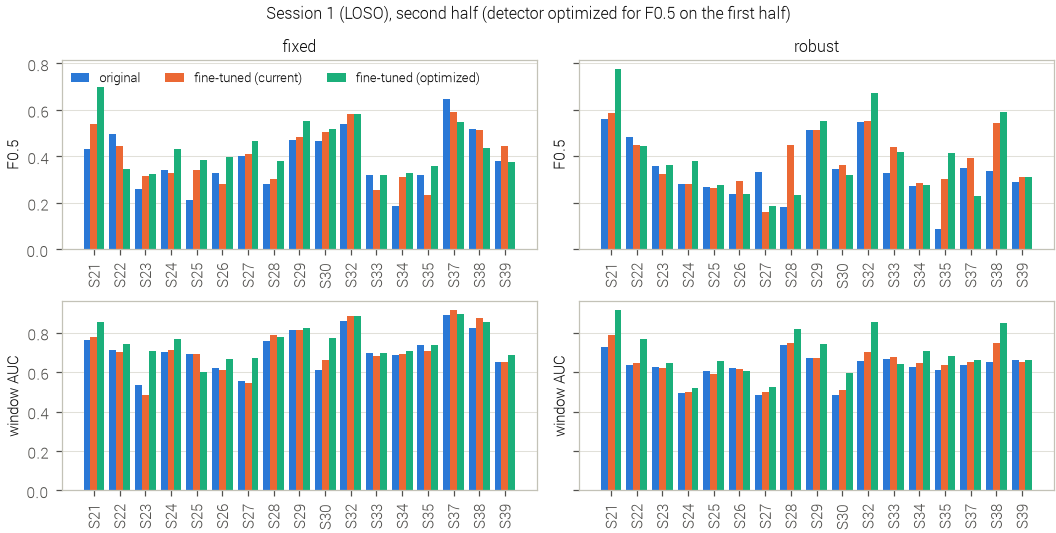

In [12]:
def per_subject_plot(rows, detector, title):
    sel = rows[rows.detector == detector]
    fig, axes = plt.subplots(2, len(MODELS), figsize=(TEXT_W, 3.6), layout='constrained', sharey='row', squeeze=False)
    for j, model in enumerate(MODELS):
        for i, (metric, label) in enumerate([(F_COL, f'F{F_BETA:g}'), ('auc_test', 'window AUC')]):
            ax = axes[i, j]
            piv = sel[sel.model == model].pivot(index='recording', columns='run', values=metric)[RUNS]
            x = np.arange(len(piv))
            for k, run in enumerate(RUNS):
                ax.bar(x + (k - 1) * 0.27, piv[run], width=0.27, color=CAT_COLORS[k], label=run)
            ax.set_xticks(x, [r.split('/')[0].replace('subject_', 'S') for r in piv.index], rotation=90)
            ax.set_ylabel(label)
            ax.yaxis.grid(True)
            ax.set_axisbelow(True)
            if i == 0:
                ax.set_title(model)
    axes[0, 0].legend(frameon=False, ncols=3, loc='upper left')
    fig.suptitle(title)
    enforce_font_sizes(fig)
    plt.show()

per_subject_plot(rows_test, OPT, f'Session 1 (LOSO), second half (detector optimized for F{F_BETA:g} on the first half)')

Example of the live output on the test half: p(pinch) per window, ground-truth pinches (grey) and the detections of the detector
optimized on the first half (hit: filled, false alarm: hollow).

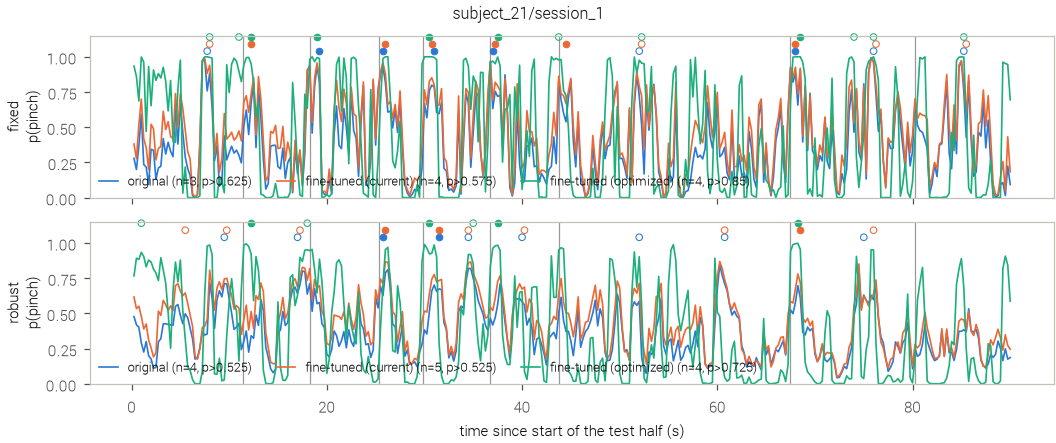

In [13]:
def trace_plot(recs, rows, traces, recording, t_from=0, duration=90, detector=OPT):
    rec = next(r for r in recs if r.name == recording)
    t0 = rec.test_intervals[0][0] + t_from
    fig, axes = plt.subplots(len(MODELS), 1, figsize=(TEXT_W, 1.3 * len(MODELS) + 0.4), layout='constrained', sharex=True, squeeze=False)
    pinches = rec.pos_ts[(rec.pos_ts >= t0) & (rec.pos_ts <= t0 + duration)]
    for ax, model in zip(axes[:, 0], MODELS):
        for k, run in enumerate(RUNS):
            if (recording, model, run) not in traces:
                continue
            t_end, p = traces[(recording, model, run)]
            row = rows[(rows.recording == recording) & (rows.model == model) & (rows.run == run) & (rows.detector == detector)].iloc[0]
            m = (t_end >= t0) & (t_end <= t0 + duration)
            ax.plot(t_end[m] - t0, p[m], color=CAT_COLORS[k], lw=0.8, label=f'{run} (n={row.consecutive}, p>{row.threshold:g})')
            det = li.lec.trigger_indices(p > row.threshold, int(row.consecutive))
            det = det[m[det] & li.in_intervals(t_end[det], rec.test_intervals)]
            hit = np.array([((pinches > t - li.WINDOW_SECONDS) & (pinches <= t)).any() for t in t_end[det]], dtype=bool)
            ax.scatter(t_end[det][hit] - t0, np.full(hit.sum(), 1.04 + 0.05 * k), color=CAT_COLORS[k], s=10, clip_on=False)
            ax.scatter(t_end[det][~hit] - t0, np.full((~hit).sum(), 1.04 + 0.05 * k), facecolor='none', edgecolor=CAT_COLORS[k], s=10, clip_on=False)
        for t in pinches:
            ax.axvline(t - t0, color='0.6', lw=0.6, zorder=0)
        ax.set_ylim(0, 1.15)
        ax.set_ylabel(f'{model}\np(pinch)')
        ax.legend(frameon=False, loc='lower left', ncols=3)
    axes[-1, 0].set_xlabel('time since start of the test half (s)')
    fig.suptitle(recording)
    enforce_font_sizes(fig)
    plt.show()

trace_plot(recs_test, rows_test, traces_test, recs_test[0].name)

## Temporal accuracy

How precisely in time are the pinches detected? The live classifier publishes a PINCH at the end of the window that completes the run of
`n` windows above the threshold; the time between the real pinch and that moment is the detection latency. For reference, the game gives
its feedback at the pinch, or 0.5 s later in the delayed-feedback condition. Not included: the inference time (about 1.4 ms per window)
and the chunking of the live stream, which can delay a classification by up to one `HOP`.

All analyses use the test half of session 1 (hinted experiments skipped) and the detector optimized for `F_BETA` on the first half, i.e. exactly the detections
counted in the result tables above.

In [14]:
LAGS = np.round(np.arange(-3, 3 + 1e-9, 0.05), 3)   # window end relative to the event (s)

def timing_tables(recs, rows, traces, detector=OPT):
    """-> (detections, locked):
    detections: one row per published PINCH on the test half, with its latency (detection - matched pinch, NaN for false alarms)
                and its offset to the nearest test pinch;
    locked: p(pinch) of the windows ending at event + LAGS, one row per test pinch / no-pinch event."""
    dets, locked = [], []
    for rec in recs:
        pinch_ts = rec.pos_ts[li.in_intervals(rec.pos_ts, rec.test_intervals)]
        neg_ts = rec.neg_ts[li.in_intervals(rec.neg_ts, rec.test_intervals)]
        for (name, model, run), (t_end, p) in traces.items():
            if name != rec.name:
                continue
            row = rows[(rows.recording == name) & (rows.model == model) & (rows.run == run) & (rows.detector == detector)].iloc[0]
            det_ts = li.detection_times(t_end, p, rec.test_intervals, int(row.consecutive), row.threshold)
            latency = li.match_latencies(det_ts, pinch_ts)
            assert np.sum(~np.isnan(latency)) == row.hits   # same detections and matching as the result tables
            if len(pinch_ts):
                offset = det_ts[:, None] - pinch_ts[None, :]
                nearest = offset[np.arange(len(det_ts)), np.abs(offset).argmin(axis=1)]
            else:
                nearest = np.full(len(det_ts), np.nan)
            dets.append(pd.DataFrame(dict(recording=name, model=model, run=run, t=det_ts, latency=latency, offset=nearest)))
            for event, ts in [('pinch', pinch_ts), ('no pinch', neg_ts)]:
                locked.append(pd.DataFrame(li.event_locked(t_end, p, ts, LAGS), columns=LAGS)
                              .assign(recording=name, model=model, run=run, event=event))
    return pd.concat(dets, ignore_index=True), pd.concat(locked, ignore_index=True)

dets_test, locked_test = timing_tables(recs_test, rows_test, traces_test)

### p(pinch) around the pinches

The classifier output time-locked to the ground-truth pinches of the test half: the x-axis is the end of the classified window relative
to the pinch (the window covers the 2 s before that point). The solid line is the pinch (0 s), the dashed line the end of a training
epoch (+0.3 s), at which the window is aligned exactly like the epochs the models were trained on. A sharp, early peak means the
classifier responds at a well-defined time after the movement; a wide plateau means a window of several hundred milliseconds in which
the run of the detector can be completed.

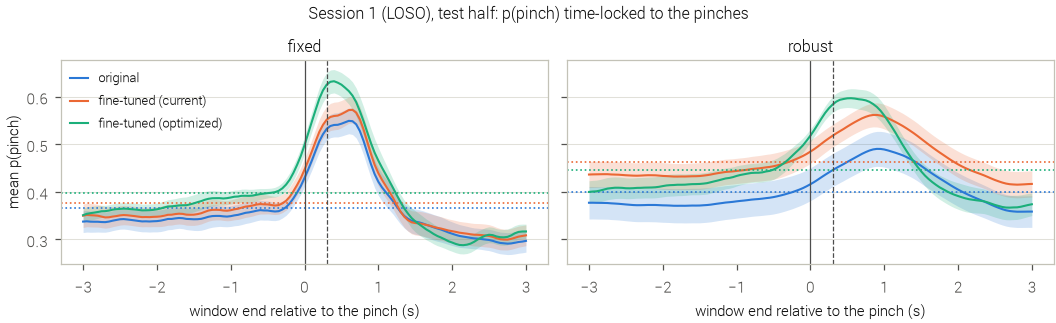

,model,run,baseline_p,peak_p,peak_lag,half_max_from,half_max_to
0,fixed,original,0.366,0.549,0.60,0.10,0.90
1,fixed,fine-tuned (current),0.377,0.572,0.65,0.10,0.90
2,fixed,fine-tuned (optimized),0.397,0.633,0.40,0.05,0.85
3,robust,original,0.400,0.490,0.90,0.30,1.55
4,robust,fine-tuned (current),0.463,0.562,0.90,0.25,1.45
5,robust,fine-tuned (optimized),0.447,0.597,0.55,0.05,1.15


In [15]:
def locked_plot(locked, title, models=None, runs=None):
    """Mean p(pinch) of the window ending `lag` after the event (averaged per recording, then mean ± SEM over recordings).
    Dotted: mean p(pinch) around the no-pinch events. Returns the peak and the half-maximum interval of the pinch curves."""
    lags = np.asarray(LAGS)
    models, runs = list(models or MODELS), list(runs or RUNS)
    fig, axes = plt.subplots(1, len(models), figsize=(TEXT_W if len(models) > 1 else COL_W, 2.2), layout='constrained', sharey=True, squeeze=False)
    peaks = []
    for ax, model in zip(axes[0], models):
        for k, run in enumerate(runs):
            curves = {event: g.groupby('recording')[list(lags)].mean()
                      for event, g in locked[(locked.model == model) & (locked.run == run)].groupby('event')}
            if 'pinch' not in curves:
                continue
            m, sem = curves['pinch'].mean().to_numpy(), curves['pinch'].sem().to_numpy()
            ax.plot(lags, m, color=CAT_COLORS[k], lw=1, label=run)
            ax.fill_between(lags, m - sem, m + sem, color=CAT_COLORS[k], alpha=0.2, lw=0)
            base = np.nanmean(curves['no pinch'].to_numpy()) if 'no pinch' in curves else np.nan
            ax.axhline(base, color=CAT_COLORS[k], lw=0.8, ls=':')
            i_peak = int(np.nanargmax(m))
            half = base + 0.5 * (m[i_peak] - base)
            below_before = np.flatnonzero(m[:i_peak] < half)
            below_after = np.flatnonzero(m[i_peak:] < half)
            peaks.append(dict(model=model, run=run, baseline_p=base, peak_p=m[i_peak], peak_lag=lags[i_peak],
                              half_max_from=lags[below_before[-1] + 1] if len(below_before) else np.nan,
                              half_max_to=lags[i_peak + below_after[0] - 1] if len(below_after) else np.nan))
        ax.axvline(0, color='0.3', lw=0.6)
        ax.axvline(li.lec.EPOCH_T_MAX, color='0.3', lw=0.6, ls='--')
        ax.yaxis.grid(True)
        ax.set_axisbelow(True)
        ax.set_title(model)
        ax.set_xlabel('window end relative to the pinch (s)')
    axes[0, 0].set_ylabel('mean p(pinch)')
    axes[0, 0].legend(frameon=False, loc='upper left')
    fig.suptitle(title)
    enforce_font_sizes(fig)
    plt.show()
    return pd.DataFrame(peaks).round(3)

locked_plot(locked_test, 'Session 1 (LOSO), test half: p(pinch) time-locked to the pinches')

### Detection latency

Latency of every hit (time of the published PINCH − ground-truth pinch). By the hit definition it lies in (0, 2] s. A window resembles a
training pinch epoch once it ends about 0.3 s after the pinch (dashed line); a run of `n` windows needs another (n − 1) × `HOP` seconds once
the probability is above the threshold.

,model,run,n (median),hits,median (s),q25,q75,q10,q90,≤ 0.5 s,≤ 1 s
0,fixed,original,3.0,354,0.699,0.444,1.001,0.262,1.474,0.305,0.749
1,robust,original,3.0,303,1.147,0.715,1.497,0.245,1.758,0.188,0.403
2,fixed,fine-tuned (current),3.0,375,0.734,0.479,1.044,0.285,1.394,0.267,0.720
3,fixed,fine-tuned (optimized),3.0,459,0.743,0.519,1.055,0.236,1.381,0.244,0.712
4,robust,fine-tuned (current),5.0,380,1.070,0.638,1.415,0.260,1.721,0.187,0.450
5,robust,fine-tuned (optimized),5.0,335,0.957,0.638,1.324,0.312,1.673,0.194,0.552


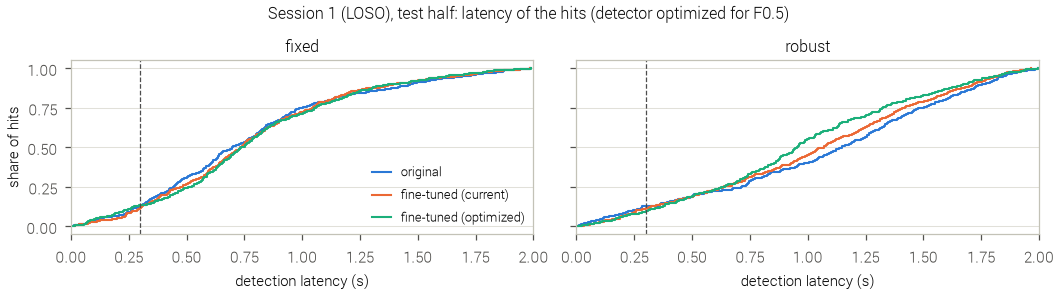

In [16]:
def latency_table(dets, rows, detector=OPT):
    """Latency (detection - pinch) of the hits, pooled over recordings; 'n (median)' is the median detector run length."""
    hits = dets.dropna(subset=['latency'])
    g = hits.groupby(['model', 'run'], sort=False).latency
    t = pd.DataFrame({
        'hits': g.size(), 'median (s)': g.median(), 'q25': g.quantile(0.25), 'q75': g.quantile(0.75),
        'q10': g.quantile(0.1), 'q90': g.quantile(0.9),
        '≤ 0.5 s': g.apply(lambda x: (x <= 0.5).mean()), '≤ 1 s': g.apply(lambda x: (x <= 1.0).mean()),
    })
    t.insert(0, 'n (median)', rows[rows.detector == detector].groupby(['model', 'run']).consecutive.median())
    return t.round(3).reset_index()

display(latency_table(dets_test, rows_test))

### Scores vs. allowed latency

The result tables count a detection as a hit if it comes up to 2 s after the pinch. Here the same detections are matched with a shorter
allowed latency: a detection that comes too late counts as a false alarm *and* its pinch as a miss. This shows how much of the
performance depends on accepting late detections.

### Timing of the false alarms

Every detection relative to the nearest test pinch. False alarms are grouped into *early* (up to 2 s before a pinch, i.e. the detector
fired before the movement), *repeat* (inside the 2 s window of a pinch that was already matched, i.e. a second trigger for the same
pinch), *late* (2–4 s after a pinch) and *unrelated* (all others). Early, repeat and late false alarms are timing errors around a real
pinch rather than detections out of nothing; the grey area marks the matching window of a hit.

Note that the pinches are dense (median gap about 6 s), so even false alarms at random times would fall into *early* about a third of the
time; a share clearly above that, and a histogram rising towards 0 s, indicate detections that come too early.

category                       false alarms  early (≤ 2 s before a pinch)  late (2–4 s after a pinch)  repeat (≤ 2 s after a matched pinch)  unrelated
model  run                                                                                                                                            
fixed  original                         444                         0.369                       0.155                                 0.029      0.446
       fine-tuned (current)             422                         0.400                       0.147                                 0.026      0.427
       fine-tuned (optimized)           533                         0.379                       0.137                                 0.021      0.463
robust original                         424                         0.427                       0.193                                 0.005      0.375
       fine-tuned (current)             511                         0.397                       0.188                                 0.010      0.405
       fine-tuned (optimized)           358                         0.425                       0.134                                 0.006      0.436

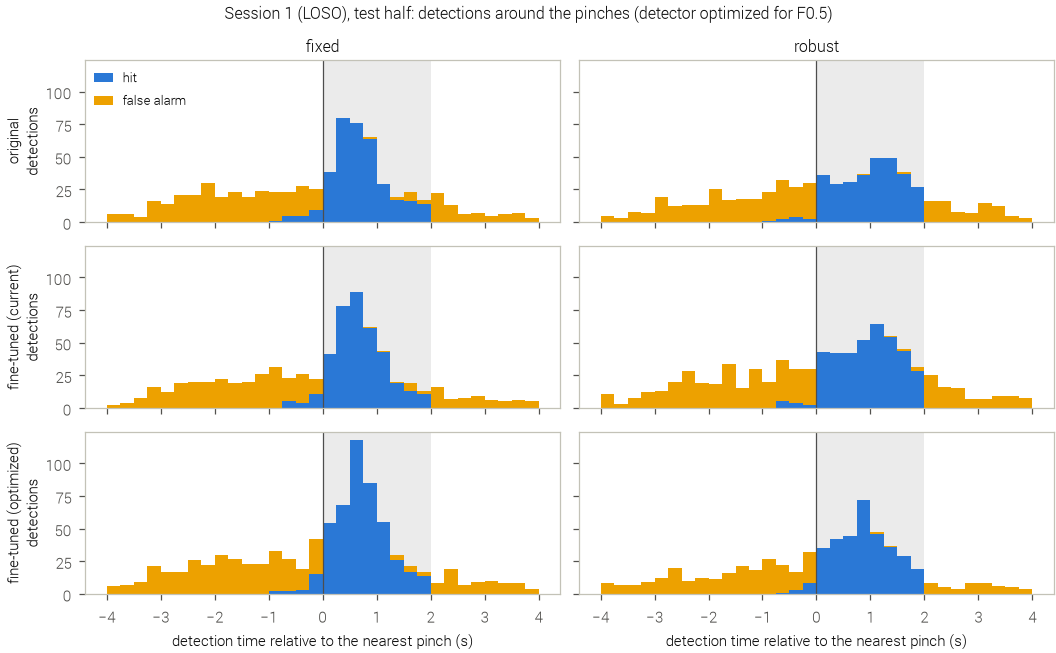

In [18]:
def false_alarm_timing(dets):
    """Share of the false alarms per timing category, by the offset to the nearest test pinch."""
    fa = dets[dets.latency.isna()].copy()
    o = fa.offset
    fa['category'] = np.select(
        [(o >= -li.WINDOW_SECONDS) & (o <= 0), (o > 0) & (o <= li.WINDOW_SECONDS), (o > li.WINDOW_SECONDS) & (o <= 2 * li.WINDOW_SECONDS)],
        ['early (≤ 2 s before a pinch)', 'repeat (≤ 2 s after a matched pinch)', 'late (2–4 s after a pinch)'],
        'unrelated')
    t = pd.crosstab([fa.model, fa.run], fa.category, normalize='index').round(3)
    t.insert(0, 'false alarms', fa.groupby(['model', 'run']).size())
    t = t.reindex([(m, r) for m in MODELS for r in RUNS]).dropna(how='all')
    return t.astype({'false alarms': int})

def offset_plot(dets, title, bins=np.arange(-4, 4 + 1e-9, 0.25), models=None, runs=None, save_as=None):
    models = list(models or MODELS)
    runs = [r for r in (runs or RUNS) if r in dets.run.unique()]
    fig, axes = plt.subplots(len(runs), len(models), figsize=(TEXT_W if len(models) > 1 else COL_W, 1.3 * len(runs) + 0.5), layout='constrained',
                             sharex=True, sharey=True, squeeze=False)
    for i, run in enumerate(runs):
        for j, model in enumerate(models):
            ax = axes[i, j]
            d = dets[(dets.model == model) & (dets.run == run)]
            ax.axvspan(0, li.WINDOW_SECONDS, color='0.92', zorder=0, lw=0)   # matching window of a hit
            ax.hist([d.offset[d.latency.notna()], d.offset[d.latency.isna()]], bins=bins, stacked=True,
                    color=[CAT_COLORS[0], CAT_COLORS[3]], label=['hit', 'false alarm'])
            ax.axvline(0, color='0.3', lw=0.6)
            if i == 0:
                ax.set_title(model)
            if j == 0:
                ax.set_ylabel(f'{run}\ndetections')
    for ax in axes[-1]:
        ax.set_xlabel('detection time relative to the nearest pinch (s)')
    axes[0, 0].legend(frameon=False, loc='upper left')
    fig.suptitle(title)
    enforce_font_sizes(fig)
    plt.show()
    if save_as is not None:
        fig.savefig(OUT_DIR_FIG / save_as)

display(false_alarm_timing(dets_test))
offset_plot(dets_test, f'Session 1 (LOSO), test half: detections around the pinches (detector optimized for F{F_BETA:g})')

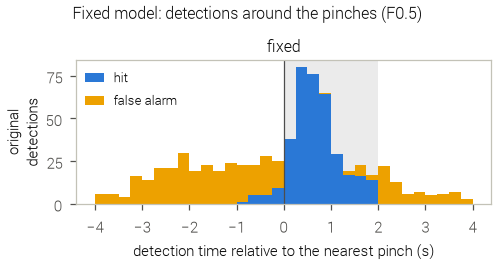

In [19]:
# the same plot for the original fixed model only
FIXED_ORIGINAL = dict(models=['fixed'], runs=['original'])
dets_fixed_orig = dets_test[(dets_test.model == 'fixed') & (dets_test.run == 'original')]
locked_fixed_orig = locked_test[(locked_test.model == 'fixed') & (locked_test.run == 'original')]
offset_plot(dets_fixed_orig, f'Fixed model: detections around the pinches (F{F_BETA:g})', **FIXED_ORIGINAL, save_as="pinch_hit_delay.pdf")

,model,run,n (median),hits,median (s),q25,q75,q10,q90,≤ 0.5 s,≤ 1 s
0,fixed,original,3.0,354,0.699,0.444,1.001,0.262,1.474,0.305,0.749


,category,false alarms,early (≤ 2 s before a pinch),late (2–4 s after a pinch),repeat (≤ 2 s after a matched pinch),unrelated
model,run,,,,,
fixed,original,444,0.369,0.155,0.029,0.446


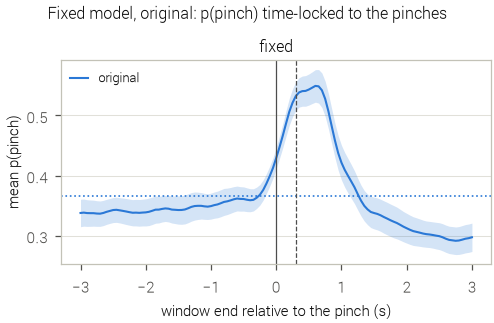

,model,run,baseline_p,peak_p,peak_lag,half_max_from,half_max_to
0,fixed,original,0.366,0.549,0.6,0.1,0.9


In [20]:
# timing of the detections shown in the fixed / original offset plot (session 1, test half)
display(latency_table(dets_fixed_orig, rows_test))
display(false_alarm_timing(dets_fixed_orig))
display(locked_plot(locked_fixed_orig, 'Fixed model, original: p(pinch) time-locked to the pinches', **FIXED_ORIGINAL))